We use a noise equivalent angle (NEA) of 1.93 with STRAP in the MAOS sims. I want to know what magnitude guide star that corresponds to so I can set the same signal level in TRICK

In [1]:
from paarti.utils import maos_utils as mu
import matplotlib.pyplot as plt
import numpy as np
from astropy import units as u

In [ ]:
# Double check I know how this all works
ngs_mag = 10
wfs = "STRAP"
r0z = 0.14
zenith_angle = 30 * u.deg
r0 = r0z * np.cos(zenith_angle.to_value(u.radian))**(3/5)
wfs_int_time = 1/472
SNR, sigma_theta, Np, Nb = mu.keck_nea_photons(ngs_mag, wfs, r0, wfs_int_time=wfs_int_time)
print(sigma_theta)

Assumptions:
  Wave-Front Sensor       = STRAP
  Pupil Aperture Diameter = 9.57 m (assumed square)
  Throughput (w QE)       = 0.32
  Plate Scale             = 1.400 arcsec/pix
  Spot Size Diameter      = 1.183 arcsec
  Filter                  = R
  Readnoise               = 0.0 e-
  Pixels per Subaperture  = 4
  Integration Time        = 0.0021 s
  Guide Star Magnitude    = 10.00

Outputs:
  N_photons from star (powfs.siglev for MAOS config): 64529.033
  N_photons per pixel from background (powfs.bkgrnd): 9.594
  SNR: 253.950
  NEA (powfs.nearecon): 4.659 mas
4.659470177207891


In [3]:
r0z = 0.14
r0 = r0z * np.cos(zenith_angle.to_value(u.radian))**(3/5)
print(r0)

0.12842406564993625


Assumptions:
  Wave-Front Sensor       = STRAP
  Pupil Aperture Diameter = 9.57 m (assumed square)
  Throughput (w QE)       = 0.32
  Plate Scale             = 1.400 arcsec/pix
  Spot Size Diameter      = 1.183 arcsec
  Filter                  = R
  Readnoise               = 0.0 e-
  Pixels per Subaperture  = 4
  Integration Time        = 0.0021 s
  Guide Star Magnitude    = 6.00

Outputs:
  N_photons from star (powfs.siglev for MAOS config): 2568947.088
  N_photons per pixel from background (powfs.bkgrnd): 9.594
  SNR: 1602.782
  NEA (powfs.nearecon): 0.738 mas
Assumptions:
  Wave-Front Sensor       = STRAP
  Pupil Aperture Diameter = 9.57 m (assumed square)
  Throughput (w QE)       = 0.32
  Plate Scale             = 1.400 arcsec/pix
  Spot Size Diameter      = 1.183 arcsec
  Filter                  = R
  Readnoise               = 0.0 e-
  Pixels per Subaperture  = 4
  Integration Time        = 0.0021 s
  Guide Star Magnitude    = 6.01

Outputs:
  N_photons from star (powfs.siglev fo

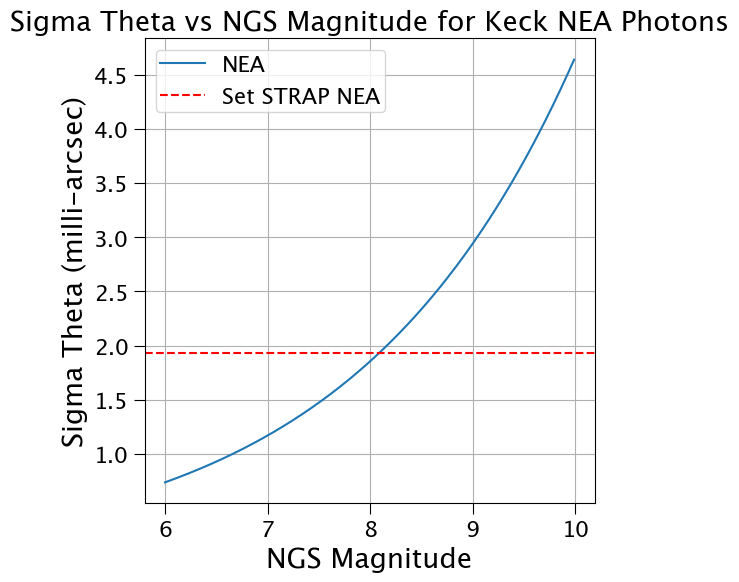

In [3]:
# Do a search over a range of ngs_mags to find the sigma_theta closest to 1.93
ngs_mags = np.arange(6, 10, 0.01)
sigma_thetas = []
for ngs_mag in ngs_mags:
    wfs = "STRAP"
    r0z = 0.14
    zenith_angle = 30 * u.deg
    r0 = r0z * np.cos(zenith_angle.to_value(u.radian))**(3/5)
    wfs_int_time = 1/472
    SNR, sigma_theta, Np, Nb = mu.keck_nea_photons(ngs_mag, wfs, r0, wfs_int_time=wfs_int_time)
    sigma_thetas.append(sigma_theta)
    
# Plot results
plt.plot(ngs_mags, sigma_thetas, label="NEA")
plt.axhline(1.93, color='r', linestyle='--', label="Set STRAP NEA")
plt.xlabel('NGS Magnitude')
plt.ylabel('Sigma Theta (milli-arcsec)')
plt.title('Sigma Theta vs NGS Magnitude for Keck NEA Photons')
plt.grid()
plt.legend()
plt.show()


In [4]:
# Use code to find the ngs_mag that gives sigma_theta closest to 1.93
closest_index = np.argmin(np.abs(np.array(sigma_thetas) - 1.93))
closest_ngs_mag = ngs_mags[closest_index]
print(f"Closest NGS Magnitude for sigma_theta ~ 1.93: {closest_ngs_mag:.2f}, Sigma Theta: {sigma_thetas[closest_index]:.2f}")

Closest NGS Magnitude for sigma_theta ~ 1.93: 8.09, Sigma Theta: 1.93


In [5]:
# Now plug this NGS magnitude in for TRICK
ngs_mag = closest_ngs_mag
wfs = "TRICK-K"
r0z = 0.14
zenith_angle = 30 * u.deg
r0 = r0z * np.cos(zenith_angle.to_value(u.radian))**(3/5)
wfs_int_time = 1/472
SNR, sigma_theta, Np, Nb = mu.keck_nea_photons(ngs_mag, wfs, r0, wfs_int_time=wfs_int_time)

Assumptions:
  Wave-Front Sensor       = TRICK-K
  Pupil Aperture Diameter = 9.57 m (assumed square)
  Throughput (w QE)       = 0.50
  Plate Scale             = 0.040 arcsec/pix
  Spot Size Diameter      = 0.074 arcsec
  Filter                  = K
  Readnoise               = 11.188 e-
  Pixels per Subaperture  = 16
  Integration Time        = 0.0021 s
  Guide Star Magnitude    = 8.09

Outputs:
  N_photons from star (powfs.siglev for MAOS config): 137134.570
  N_photons per pixel from background (powfs.bkgrnd): 3.446
  SNR: 367.569
  NEA (powfs.nearecon): 0.201 mas


In [6]:
closest_ngs_mag

8.089999999999955

In [7]:
# Try TRICK-K with different r0 and gs mag to match TRICK_on_sky
ngs_mag = 11.1
wfs = "TRICK-K"
r0z = 0.29
zenith_angle = 30 * u.deg
r0 = r0z * np.cos(zenith_angle.to_value(u.radian))**(3/5)
wfs_int_time = 1/472
SNR, sigma_theta, Np, Nb = mu.keck_nea_photons(ngs_mag, wfs, r0, wfs_int_time=wfs_int_time)

Assumptions:
  Wave-Front Sensor       = TRICK-K
  Pupil Aperture Diameter = 9.57 m (assumed square)
  Throughput (w QE)       = 0.50
  Plate Scale             = 0.040 arcsec/pix
  Spot Size Diameter      = 0.074 arcsec
  Filter                  = K
  Readnoise               = 11.188 e-
  Pixels per Subaperture  = 16
  Integration Time        = 0.0021 s
  Guide Star Magnitude    = 11.10

Outputs:
  N_photons from star (powfs.siglev for MAOS config): 8573.279
  N_photons per pixel from background (powfs.bkgrnd): 3.446
  SNR: 83.149
  NEA (powfs.nearecon): 0.890 mas


In [8]:
# Now plug this NGS magnitude in for TRICK
ngs_mag = closest_ngs_mag
wfs = "TRICK-H"
r0z = 0.14
zenith_angle = 30 * u.deg
r0 = r0z * np.cos(zenith_angle.to_value(u.radian))**(3/5)
wfs_int_time = 1/472
SNR, sigma_theta, Np, Nb = mu.keck_nea_photons(ngs_mag, wfs, r0, wfs_int_time=wfs_int_time)

Assumptions:
  Wave-Front Sensor       = TRICK-H
  Pupil Aperture Diameter = 9.57 m (assumed square)
  Throughput (w QE)       = 0.45
  Plate Scale             = 0.060 arcsec/pix
  Spot Size Diameter      = 0.055 arcsec
  Filter                  = H
  Readnoise               = 11.188 e-
  Pixels per Subaperture  = 16
  Integration Time        = 0.0021 s
  Guide Star Magnitude    = 8.09

Outputs:
  N_photons from star (powfs.siglev for MAOS config): 123990.386
  N_photons per pixel from background (powfs.bkgrnd): 3.355
  SNR: 349.238
  NEA (powfs.nearecon): 0.157 mas


In [9]:
# Try TRICK-K with a read noise of 5 electrons
ngs_mag = closest_ngs_mag
wfs = "TRICK-K_5rne"
r0z = 0.14
zenith_angle = 30 * u.deg
r0 = r0z * np.cos(zenith_angle.to_value(u.radian))**(3/5)
wfs_int_time = 1/472
SNR, sigma_theta, Np, Nb = mu.keck_nea_photons(ngs_mag, wfs, r0, wfs_int_time=wfs_int_time)

Assumptions:
  Wave-Front Sensor       = TRICK-K_5rne
  Pupil Aperture Diameter = 9.57 m (assumed square)
  Throughput (w QE)       = 0.50
  Plate Scale             = 0.040 arcsec/pix
  Spot Size Diameter      = 0.074 arcsec
  Filter                  = K
  Readnoise               = 5 e-
  Pixels per Subaperture  = 16
  Integration Time        = 0.0021 s
  Guide Star Magnitude    = 8.09

Outputs:
  N_photons from star (powfs.siglev for MAOS config): 137134.570
  N_photons per pixel from background (powfs.bkgrnd): 3.446
  SNR: 369.704
  NEA (powfs.nearecon): 0.200 mas


In [10]:
# Try TRICK-H with a read noise of 5 electrons
ngs_mag = closest_ngs_mag
wfs = "TRICK-H_5rne"
r0z = 0.14
zenith_angle = 30 * u.deg
r0 = r0z * np.cos(zenith_angle.to_value(u.radian))**(3/5)
wfs_int_time = 1/472
SNR, sigma_theta, Np, Nb = mu.keck_nea_photons(ngs_mag, wfs, r0, wfs_int_time=wfs_int_time)

Assumptions:
  Wave-Front Sensor       = TRICK-H_5rne
  Pupil Aperture Diameter = 9.57 m (assumed square)
  Throughput (w QE)       = 0.45
  Plate Scale             = 0.060 arcsec/pix
  Spot Size Diameter      = 0.055 arcsec
  Filter                  = H
  Readnoise               = 5 e-
  Pixels per Subaperture  = 16
  Integration Time        = 0.0021 s
  Guide Star Magnitude    = 8.09

Outputs:
  N_photons from star (powfs.siglev for MAOS config): 123990.386
  N_photons per pixel from background (powfs.bkgrnd): 3.355
  SNR: 351.480
  NEA (powfs.nearecon): 0.156 mas


In [11]:
# Now plug this NGS magnitude in for TRICK
ngs_mag = closest_ngs_mag
wfs = "TREAT-K"
r0z = 0.14
zenith_angle = 30 * u.deg
r0 = r0z * np.cos(zenith_angle.to_value(u.radian))**(3/5)
wfs_int_time = 1/472
SNR, sigma_theta, Np, Nb = mu.keck_nea_photons(ngs_mag, wfs, r0, wfs_int_time=wfs_int_time)

Assumptions:
  Wave-Front Sensor       = TREAT-K
  Pupil Aperture Diameter = 9.57 m (assumed square)
  Throughput (w QE)       = 0.50
  Plate Scale             = 0.053 arcsec/pix
  Spot Size Diameter      = 0.074 arcsec
  Filter                  = K
  Readnoise               = 0.5 e-
  Pixels per Subaperture  = 16
  Integration Time        = 0.0021 s
  Guide Star Magnitude    = 8.09

Outputs:
  N_photons from star (powfs.siglev for MAOS config): 137134.570
  N_photons per pixel from background (powfs.bkgrnd): 6.126
  SNR: 370.179
  NEA (powfs.nearecon): 0.200 mas


In [12]:
# Now plug this NGS magnitude in for TRICK
ngs_mag = closest_ngs_mag
wfs = "TREAT-H"
r0z = 0.14
zenith_angle = 30 * u.deg
r0 = r0z * np.cos(zenith_angle.to_value(u.radian))**(3/5)
wfs_int_time = 1/472
SNR, sigma_theta, Np, Nb = mu.keck_nea_photons(ngs_mag, wfs, r0, wfs_int_time=wfs_int_time)

Assumptions:
  Wave-Front Sensor       = TREAT-H
  Pupil Aperture Diameter = 9.57 m (assumed square)
  Throughput (w QE)       = 0.45
  Plate Scale             = 0.080 arcsec/pix
  Spot Size Diameter      = 0.055 arcsec
  Filter                  = H
  Readnoise               = 0.5 e-
  Pixels per Subaperture  = 16
  Integration Time        = 0.0021 s
  Guide Star Magnitude    = 8.09

Outputs:
  N_photons from star (powfs.siglev for MAOS config): 123990.386
  N_photons per pixel from background (powfs.bkgrnd): 5.964
  SNR: 351.982
  NEA (powfs.nearecon): 0.156 mas


Assumptions:
  Wave-Front Sensor       = TREAT-K
  Pupil Aperture Diameter = 9.57 m (assumed square)
  Throughput (w QE)       = 0.50
  Plate Scale             = 0.053 arcsec/pix
  Spot Size Diameter      = 0.074 arcsec
  Filter                  = K
  Readnoise               = 0.5 e-
  Pixels per Subaperture  = 16
  Integration Time        = 0.0021 s
  Guide Star Magnitude    = 8.00

Outputs:
  N_photons from star (powfs.siglev for MAOS config): 148986.511
  N_photons per pixel from background (powfs.bkgrnd): 6.126
  SNR: 385.856
  NEA (powfs.nearecon): 0.192 mas
Assumptions:
  Wave-Front Sensor       = TREAT-K
  Pupil Aperture Diameter = 9.57 m (assumed square)
  Throughput (w QE)       = 0.50
  Plate Scale             = 0.053 arcsec/pix
  Spot Size Diameter      = 0.074 arcsec
  Filter                  = K
  Readnoise               = 0.5 e-
  Pixels per Subaperture  = 16
  Integration Time        = 0.0021 s
  Guide Star Magnitude    = 8.10

Outputs:
  N_photons from star (powfs.sigle

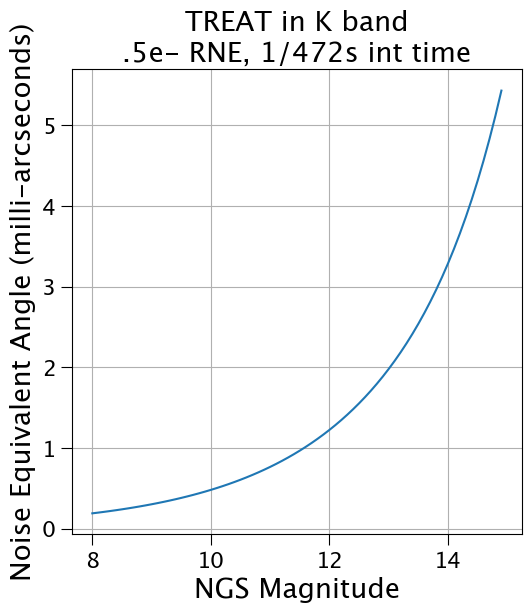

In [13]:
# Look at TREAT-K as a function of ngs_mag
ngs_mags = np.arange(8, 15, 0.1)
sigma_thetas = []
for ngs_mag in ngs_mags:
    wfs = "TREAT-K"
    r0z = 0.14
    zenith_angle = 30 * u.deg
    r0 = r0z * np.cos(zenith_angle.to_value(u.radian))**(3/5)
    wfs_int_time = 1/472
    SNR, sigma_theta, Np, Nb = mu.keck_nea_photons(ngs_mag, wfs, r0, wfs_int_time=wfs_int_time)
    sigma_thetas.append(sigma_theta)

# Make plot
plt.plot(ngs_mags, sigma_thetas)
plt.xlabel('NGS Magnitude')
plt.ylabel('Noise Equivalent Angle (milli-arcseconds)')
plt.title("TREAT in K band\n.5e- RNE, 1/472s int time")
plt.grid()
plt.show()

Assumptions:
  Wave-Front Sensor       = TREAT-K
  Pupil Aperture Diameter = 9.57 m (assumed square)
  Throughput (w QE)       = 0.50
  Plate Scale             = 0.053 arcsec/pix
  Spot Size Diameter      = 0.074 arcsec
  Filter                  = K
  Readnoise               = 0.5 e-
  Pixels per Subaperture  = 16
  Integration Time        = 0.0020 s
  Guide Star Magnitude    = 8.32

Outputs:
  N_photons from star (powfs.siglev for MAOS config): 104741.538
  N_photons per pixel from background (powfs.bkgrnd): 5.783
  SNR: 323.489
  NEA (powfs.nearecon): 0.229 mas
Assumptions:
  Wave-Front Sensor       = TREAT-K
  Pupil Aperture Diameter = 9.57 m (assumed square)
  Throughput (w QE)       = 0.50
  Plate Scale             = 0.053 arcsec/pix
  Spot Size Diameter      = 0.074 arcsec
  Filter                  = K
  Readnoise               = 0.5 e-
  Pixels per Subaperture  = 16
  Integration Time        = 0.0017 s
  Guide Star Magnitude    = 8.32

Outputs:
  N_photons from star (powfs.sigle

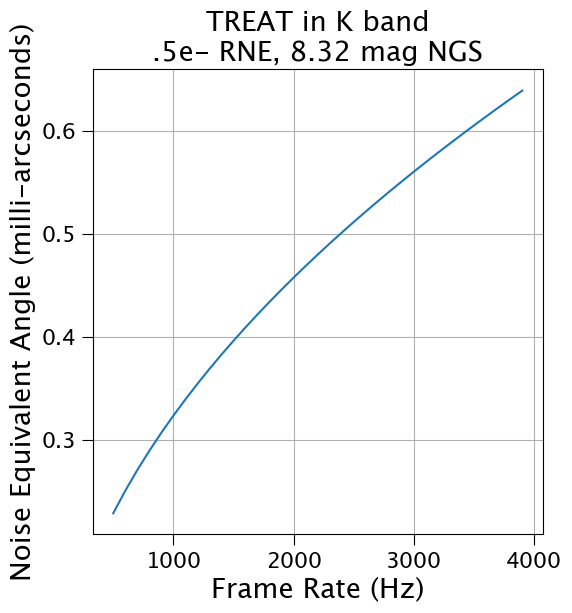

In [14]:
# Look at TREAT-K as a function of wfs_int_time
frame_rates = np.arange(500, 4000, 100)
wfs_int_times = [1 / frame_rate for frame_rate in frame_rates]
sigma_thetas = []
for wfs_int_time in wfs_int_times:
    ngs_mag = 8.32
    wfs = "TREAT-K"
    r0z = 0.14
    zenith_angle = 30 * u.deg
    r0 = r0z * np.cos(zenith_angle.to_value(u.radian))**(3/5)
    SNR, sigma_theta, Np, Nb = mu.keck_nea_photons(ngs_mag, wfs, r0, wfs_int_time=wfs_int_time)
    sigma_thetas.append(sigma_theta)

# Make plot
plt.plot(frame_rates, sigma_thetas)
plt.xlabel('Frame Rate (Hz)')
plt.ylabel('Noise Equivalent Angle (milli-arcseconds)')
plt.title("TREAT in K band\n.5e- RNE, 8.32 mag NGS")
plt.grid()
plt.show()

In [15]:
ngs_mag = 10.83
wfs = "TREAT-K"
r0z = 0.14
zenith_angle = 30 * u.deg
r0 = r0z * np.cos(zenith_angle.to_value(u.radian))**(3/5)
wfs_int_time = 1/3500
SNR, sigma_theta, Np, Nb = mu.keck_nea_photons(ngs_mag, wfs, r0, wfs_int_time=wfs_int_time)
print(sigma_theta)

Assumptions:
  Wave-Front Sensor       = TREAT-K
  Pupil Aperture Diameter = 9.57 m (assumed square)
  Throughput (w QE)       = 0.50
  Plate Scale             = 0.053 arcsec/pix
  Spot Size Diameter      = 0.074 arcsec
  Filter                  = K
  Readnoise               = 0.5 e-
  Pixels per Subaperture  = 16
  Integration Time        = 0.0003 s
  Guide Star Magnitude    = 10.83

Outputs:
  N_photons from star (powfs.siglev for MAOS config): 1482.589
  N_photons per pixel from background (powfs.bkgrnd): 0.826
  SNR: 38.283
  NEA (powfs.nearecon): 1.933 mas
1.9329848364343887


Assumptions:
  Wave-Front Sensor       = TRICK-K
  Pupil Aperture Diameter = 9.57 m (assumed square)
  Throughput (w QE)       = 0.50
  Plate Scale             = 0.040 arcsec/pix
  Spot Size Diameter      = 0.074 arcsec
  Filter                  = K
  Readnoise               = 11.188 e-
  Pixels per Subaperture  = 16
  Integration Time        = 0.0020 s
  Guide Star Magnitude    = 8.32

Outputs:
  N_photons from star (powfs.siglev for MAOS config): 104741.538
  N_photons per pixel from background (powfs.bkgrnd): 3.253
  SNR: 320.509
  NEA (powfs.nearecon): 0.231 mas
Assumptions:
  Wave-Front Sensor       = TREAT-K
  Pupil Aperture Diameter = 9.57 m (assumed square)
  Throughput (w QE)       = 0.50
  Plate Scale             = 0.053 arcsec/pix
  Spot Size Diameter      = 0.074 arcsec
  Filter                  = K
  Readnoise               = 0.5 e-
  Pixels per Subaperture  = 16
  Integration Time        = 0.0020 s
  Guide Star Magnitude    = 8.32

Outputs:
  N_photons from star (powfs.si

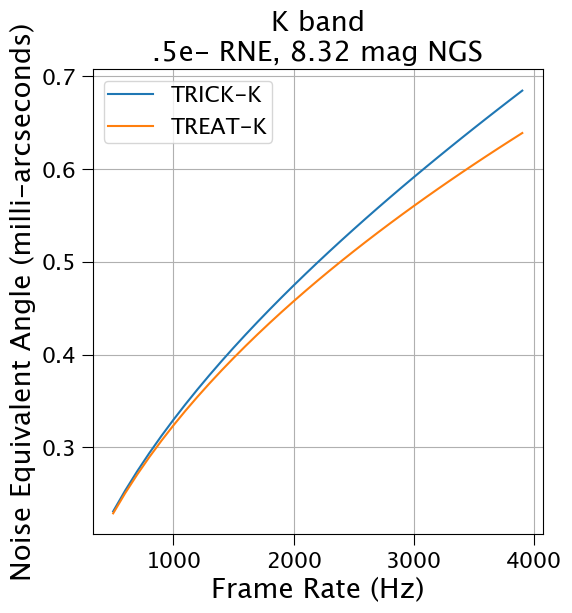

In [16]:
# Look at TREAT-K as a function of wfs_int_time
frame_rates = np.arange(500, 4000, 100)
wfs_int_times = [1 / frame_rate for frame_rate in frame_rates]
TRICK_K_sigma_thetas = []
TREAT_K_sigma_thetas = []
for wfs_int_time in wfs_int_times:
    ngs_mag = 8.32
    wfs = "TRICK-K"
    r0z = 0.14
    zenith_angle = 30 * u.deg
    r0 = r0z * np.cos(zenith_angle.to_value(u.radian))**(3/5)
    SNR, sigma_theta, Np, Nb = mu.keck_nea_photons(ngs_mag, wfs, r0, wfs_int_time=wfs_int_time)
    TRICK_K_sigma_thetas.append(sigma_theta)
    wfs = "TREAT-K"
    SNR, sigma_theta, Np, Nb = mu.keck_nea_photons(ngs_mag, wfs, r0, wfs_int_time=wfs_int_time)
    TREAT_K_sigma_thetas.append(sigma_theta)

# Make plot
plt.plot(frame_rates, TRICK_K_sigma_thetas, label='TRICK-K')
plt.plot(frame_rates, TREAT_K_sigma_thetas, label='TREAT-K')
plt.xlabel('Frame Rate (Hz)')
plt.ylabel('Noise Equivalent Angle (milli-arcseconds)')
plt.title("K band\n.5e- RNE, 8.32 mag NGS")
plt.legend()
plt.grid()
plt.show()

Assumptions:
  Wave-Front Sensor       = TREAT-K
  Pupil Aperture Diameter = 9.57 m (assumed square)
  Throughput (w QE)       = 0.50
  Plate Scale             = 0.053 arcsec/pix
  Spot Size Diameter      = 0.074 arcsec
  Filter                  = K
  Readnoise               = 0.5 e-
  Pixels per Subaperture  = 16
  Integration Time        = 0.0010 s
  Guide Star Magnitude    = 8.00

Outputs:
  N_photons from star (powfs.siglev for MAOS config): 70321.633
  N_photons per pixel from background (powfs.bkgrnd): 2.891
  SNR: 265.088
  NEA (powfs.nearecon): 0.279 mas
Assumptions:
  Wave-Front Sensor       = TRICK-K
  Pupil Aperture Diameter = 9.57 m (assumed square)
  Throughput (w QE)       = 0.50
  Plate Scale             = 0.040 arcsec/pix
  Spot Size Diameter      = 0.074 arcsec
  Filter                  = K
  Readnoise               = 11.188 e-
  Pixels per Subaperture  = 16
  Integration Time        = 0.0010 s
  Guide Star Magnitude    = 8.00

Outputs:
  N_photons from star (powfs.sig

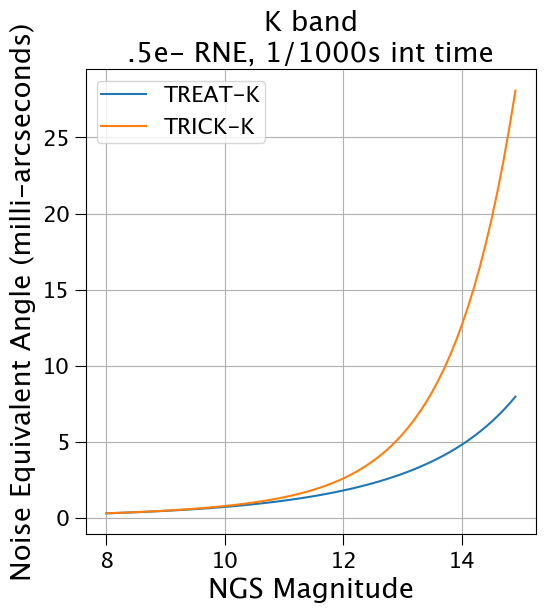

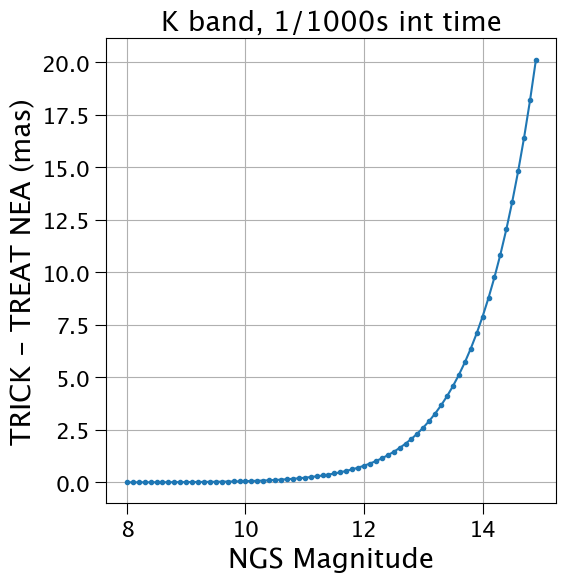

In [17]:
# Look at TREAT-K as a function of ngs_mag
ngs_mags = np.arange(8, 15, 0.1)
TREAT_K_sigma_thetas = []
TRICK_K_sigma_thetas = []
for ngs_mag in ngs_mags:
    wfs = "TREAT-K"
    r0z = 0.14
    zenith_angle = 30 * u.deg
    r0 = r0z * np.cos(zenith_angle.to_value(u.radian))**(3/5)
    frame_rate = 1000
    wfs_int_time = 1/frame_rate
    SNR, sigma_theta, Np, Nb = mu.keck_nea_photons(ngs_mag, wfs, r0, wfs_int_time=wfs_int_time)
    TREAT_K_sigma_thetas.append(sigma_theta)
    wfs = "TRICK-K"
    SNR, sigma_theta, Np, Nb = mu.keck_nea_photons(ngs_mag, wfs, r0, wfs_int_time=wfs_int_time)
    TRICK_K_sigma_thetas.append(sigma_theta)

# Make plot
plt.plot(ngs_mags, TREAT_K_sigma_thetas, label='TREAT-K')
plt.plot(ngs_mags, TRICK_K_sigma_thetas, label='TRICK-K')
plt.xlabel('NGS Magnitude')
plt.ylabel('Noise Equivalent Angle (milli-arcseconds)')
plt.title(f"K band\n.5e- RNE, 1/{frame_rate}s int time")
plt.grid()
plt.legend()
plt.show()

difference = np.array(TRICK_K_sigma_thetas) - np.array(TREAT_K_sigma_thetas)
plt.plot(ngs_mags, difference, marker='.')
plt.xlabel('NGS Magnitude')
plt.ylabel('TRICK - TREAT NEA (mas)')
plt.title(f"K band, 1/{frame_rate}s int time")
plt.grid()
plt.show()

In [18]:
# Now plug this NGS magnitude in for TRICK
ngs_mag = closest_ngs_mag
print("closest_ngs_mag:", closest_ngs_mag)
wfs = "TRICK-K"
r0z = 0.14
zenith_angle = 30 * u.deg
r0 = r0z * np.cos(zenith_angle.to_value(u.radian))**(3/5)
wfs_int_time = 1/472
SNR, sigma_theta, Np, Nb = mu.keck_nea_photons(ngs_mag, wfs, r0, wfs_int_time=wfs_int_time)
print("NEA:", sigma_theta)

closest_ngs_mag: 8.089999999999955
Assumptions:
  Wave-Front Sensor       = TRICK-K
  Pupil Aperture Diameter = 9.57 m (assumed square)
  Throughput (w QE)       = 0.50
  Plate Scale             = 0.040 arcsec/pix
  Spot Size Diameter      = 0.074 arcsec
  Filter                  = K
  Readnoise               = 11.188 e-
  Pixels per Subaperture  = 16
  Integration Time        = 0.0021 s
  Guide Star Magnitude    = 8.09

Outputs:
  N_photons from star (powfs.siglev for MAOS config): 137134.570
  N_photons per pixel from background (powfs.bkgrnd): 3.446
  SNR: 367.569
  NEA (powfs.nearecon): 0.201 mas
NEA: 0.20132263037844325


In [19]:
ngs_mag = closest_ngs_mag
wfs = "TRICK-K"
r0 = 0.272
wfs_int_time = 1/472 # dtref
_, sigma_theta, _, _ = mu.keck_nea_photons(ngs_mag, wfs, r0, wfs_int_time=wfs_int_time)
print("NEA:", sigma_theta)

Assumptions:
  Wave-Front Sensor       = TRICK-K
  Pupil Aperture Diameter = 9.57 m (assumed square)
  Throughput (w QE)       = 0.50
  Plate Scale             = 0.040 arcsec/pix
  Spot Size Diameter      = 0.074 arcsec
  Filter                  = K
  Readnoise               = 11.188 e-
  Pixels per Subaperture  = 16
  Integration Time        = 0.0021 s
  Guide Star Magnitude    = 8.09

Outputs:
  N_photons from star (powfs.siglev for MAOS config): 137134.570
  N_photons per pixel from background (powfs.bkgrnd): 3.446
  SNR: 367.569
  NEA (powfs.nearecon): 0.201 mas
NEA: 0.20132263037844325


In [20]:
for r0z in [0.14, 0.272]:
    # ngs_mag = 11.1
    ngs_mag = closest_ngs_mag
    wfs = "TRICK-K"
    zenith_angle = 30 * u.deg
    r0 = r0z * np.cos(zenith_angle.to_value(u.radian))**(3/5)
    wfs_int_time = 1/472 # dtref
    _, sigma_theta, _, _ = mu.keck_nea_photons(ngs_mag, wfs, r0, wfs_int_time=wfs_int_time)
    print("NEA:", sigma_theta)

Assumptions:
  Wave-Front Sensor       = TRICK-K
  Pupil Aperture Diameter = 9.57 m (assumed square)
  Throughput (w QE)       = 0.50
  Plate Scale             = 0.040 arcsec/pix
  Spot Size Diameter      = 0.074 arcsec
  Filter                  = K
  Readnoise               = 11.188 e-
  Pixels per Subaperture  = 16
  Integration Time        = 0.0021 s
  Guide Star Magnitude    = 8.09

Outputs:
  N_photons from star (powfs.siglev for MAOS config): 137134.570
  N_photons per pixel from background (powfs.bkgrnd): 3.446
  SNR: 367.569
  NEA (powfs.nearecon): 0.201 mas
NEA: 0.20132263037844325
Assumptions:
  Wave-Front Sensor       = TRICK-K
  Pupil Aperture Diameter = 9.57 m (assumed square)
  Throughput (w QE)       = 0.50
  Plate Scale             = 0.040 arcsec/pix
  Spot Size Diameter      = 0.074 arcsec
  Filter                  = K
  Readnoise               = 11.188 e-
  Pixels per Subaperture  = 16
  Integration Time        = 0.0021 s
  Guide Star Magnitude    = 8.09

Outputs:
  N

In [21]:
ngs_mag = 11.1
wfs = "TRICK-K"
r0 = 0.272
wfs_int_time = 1/472 # dtref
_, sigma_theta, _, _ = mu.keck_nea_photons(ngs_mag, wfs, r0, wfs_int_time=wfs_int_time)
print("NEA:", sigma_theta)

Assumptions:
  Wave-Front Sensor       = TRICK-K
  Pupil Aperture Diameter = 9.57 m (assumed square)
  Throughput (w QE)       = 0.50
  Plate Scale             = 0.040 arcsec/pix
  Spot Size Diameter      = 0.074 arcsec
  Filter                  = K
  Readnoise               = 11.188 e-
  Pixels per Subaperture  = 16
  Integration Time        = 0.0021 s
  Guide Star Magnitude    = 11.10

Outputs:
  N_photons from star (powfs.siglev for MAOS config): 8573.279
  N_photons per pixel from background (powfs.bkgrnd): 3.446
  SNR: 83.149
  NEA (powfs.nearecon): 0.890 mas
NEA: 0.8899690362516951
